In [61]:
import pandas as pd

DATA = 'data'

DATASETS = ['coauth-MAG-Geology', 'coauth-MAG-History', 'contact-high-school', 'contact-primary-school',
            'email-Enron', 'email-Eu', 'NDC-classes', 'NDC-substances', 'tags-ask-ubuntu', 'threads-ask-ubuntu']

print(r'\begin{table}[t]')
print(r'\centering')
print(r'\caption{Datasets. Nodes and timestamped simplices in the raw data; candidates: open triangles in the test '
      r'window; closures: candidates that close; positive rate: closures / candidates.}')
print(r'\label{tab:datasets}')
print(r'\small')
print(r'\begin{tabular}{lrrrrr}')
print(r'\toprule')
print(r'Dataset & Nodes & Simplices & Candidates & Closures & Positive rate (\%) \\')
print(r'\midrule')
for ds in DATASETS:
    # raw data (Benson et al. format): one simplex size per line, then the nodes of all simplices one per line
    n_simplices = len(pd.read_csv(f'{DATA}/raw/{ds}/{ds}-nverts.txt', header=None))
    n_nodes = pd.read_csv(f'{DATA}/raw/{ds}/{ds}-simplices.txt', header=None)[0].nunique()

    # test window: candidate triangles with labels (1 = closed)
    y = pd.read_parquet(f'{DATA}/processed/{ds}/trg_open_test.parquet', columns=['y'])['y']
    n_candidates = len(y)
    n_closures = int(y.sum())

    print(f'{ds} & {n_nodes:,} & {n_simplices:,} & {n_candidates:,} & {n_closures:,} & '
          f'{n_closures / n_candidates * 100:.2f} \\\\')
print(r'\bottomrule')
print(r'\end{tabular}')
print(r'\end{table}')

\begin{table}[t]
\centering
\caption{Datasets. Nodes and timestamped simplices in the raw data; candidates: open triangles in the test window; closures: candidates that close; positive rate: closures / candidates.}
\label{tab:datasets}
\small
\begin{tabular}{lrrrrr}
\toprule
Dataset & Nodes & Simplices & Candidates & Closures & Positive rate (\%) \\
\midrule
coauth-MAG-Geology & 1,243,236 & 1,563,847 & 556,798 & 14,686 & 2.64 \\
coauth-MAG-History & 953,470 & 1,700,055 & 38,850 & 406 & 1.05 \\
contact-high-school & 327 & 172,035 & 25,788 & 186 & 0.72 \\
contact-primary-school & 242 & 106,879 & 71,157 & 746 & 1.05 \\
email-Enron & 143 & 10,883 & 3,278 & 28 & 0.85 \\
email-Eu & 998 & 232,976 & 198,212 & 3,307 & 1.67 \\
NDC-classes & 1,152 & 47,977 & 5,379 & 348 & 6.47 \\
NDC-substances & 5,247 & 110,191 & 481,011 & 26,376 & 5.48 \\
tags-ask-ubuntu & 3,029 & 270,778 & 2,770,987 & 14,222 & 0.51 \\
threads-ask-ubuntu & 125,487 & 192,625 & 122,789 & 61 & 0.05 \\
\bottomrule
\end{tabular}
\en

In [62]:
import pandas as pd

RESULTS = 'results'

DATASETS = ['coauth-MAG-Geology', 'coauth-MAG-History', 'contact-high-school', 'contact-primary-school',
            'email-Enron', 'email-Eu', 'NDC-classes', 'NDC-substances', 'tags-ask-ubuntu', 'threads-ask-ubuntu']
FEATURES = ['a', 'w', 'd', 'h', 't', 'm']      # all, weights, degrees, heuristics, time, motifs

# performance of the unsupervised baselines (AP / positive rate)
BASELINES = {
    'coauth-MAG-Geology':     {'HCN': 1.5646, 'HAA': 1.7038, 'HPA': 1.0859, 'SWA': 1.7256,  'SWG': 1.8145,  'SWH': 1.7137},
    'coauth-MAG-History':     {'HCN': 3.3487, 'HAA': 3.8942, 'HPA': 2.1176, 'SWA': 4.8290,  'SWG': 5.6508,  'SWH': 4.3489},
    'contact-high-school':    {'HCN': 1.6660, 'HAA': 1.7338, 'HPA': 0.9773, 'SWA': 2.9590,  'SWG': 4.1305,  'SWH': 3.6978},
    'contact-primary-school': {'HCN': 2.1128, 'HAA': 2.3021, 'HPA': 0.8341, 'SWA': 3.3144,  'SWG': 5.4731,  'SWH': 5.2179},
    'email-Enron':            {'HCN': 4.2332, 'HAA': 4.8926, 'HPA': 4.4434, 'SWA': 2.8335,  'SWG': 7.3681,  'SWH': 4.3785},
    'email-Eu':               {'HCN': 1.2059, 'HAA': 1.3010, 'HPA': 0.7798, 'SWA': 1.7201,  'SWG': 1.9722,  'SWH': 1.7828},
    'NDC-classes':            {'HCN': 1.5285, 'HAA': 1.3297, 'HPA': 2.1702, 'SWA': 1.1046,  'SWG': 1.3756,  'SWH': 1.4263},
    'NDC-substances':         {'HCN': 2.6368, 'HAA': 2.6817, 'HPA': 2.4891, 'SWA': 2.2003,  'SWG': 2.8192,  'SWH': 2.5855},
    'tags-ask-ubuntu':        {'HCN': 2.3872, 'HAA': 2.5033, 'HPA': 2.3255, 'SWA': 4.9768,  'SWG': 7.4204,  'SWH': 5.7571},
    'threads-ask-ubuntu':     {'HCN': 6.1801, 'HAA': 6.8488, 'HPA': 3.1958, 'SWA': 11.3249, 'SWG': 22.2064, 'SWH': 18.4103},
}

print(r'\begin{table*}[t]')
print(r'\centering')
print(r'\caption{Performance of logistic regression trained on all features and on each feature group alone, '
      r'compared with the best of six unsupervised rankings in each dataset (Appendix Table~\ref{tab:baselines}). '
      r'Mean $\pm$ std over 5 seeds; 1 = random. Bold: best value in the row.}')
print(r'\label{tab:main}')
print(r'\small')
print(r'\begin{tabular}{llcccccc}')
print(r'\toprule')
print(r'Dataset & Best baseline & All & Weights & Degrees & Heuristics & Time & Motifs \\')
print(r'\midrule')
for ds in DATASETS:
    # best of the six baselines
    b_name = max(BASELINES[ds], key=BASELINES[ds].get)
    b_value = BASELINES[ds][b_name]

    # mean and std over seeds for each feature set
    means, stds = [], []
    for f in FEATURES:
        p = pd.read_csv(f'{RESULTS}/{ds}/metrics/lr_{f}.csv')['performance']
        means.append(p.mean())
        stds.append(p.std())

    values = [b_value] + means
    best = max(values)
    cells = [f'{b_value:.2f} ({b_name})']
    cells += [f'{m:.2f} $\\pm$ {s:.2f}' for m, s in zip(means, stds)]
    cells = [f'\\textbf{{{c}}}' if v == best else c for c, v in zip(cells, values)]
    print(ds + ' & ' + ' & '.join(cells) + r' \\')
print(r'\bottomrule')
print(r'\end{tabular}')
print(r'\end{table*}')

\begin{table*}[t]
\centering
\caption{Performance of logistic regression trained on all features and on each feature group alone, compared with the best of six unsupervised rankings in each dataset (Appendix Table~\ref{tab:baselines}). Mean $\pm$ std over 5 seeds; 1 = random. Bold: best value in the row.}
\label{tab:main}
\small
\begin{tabular}{llcccccc}
\toprule
Dataset & Best baseline & All & Weights & Degrees & Heuristics & Time & Motifs \\
\midrule
coauth-MAG-Geology & 1.81 (SWG) & \textbf{3.18 $\pm$ 0.08} & 1.81 $\pm$ 0.01 & 1.05 $\pm$ 0.01 & 1.89 $\pm$ 0.01 & 2.68 $\pm$ 0.02 & 2.21 $\pm$ 0.04 \\
coauth-MAG-History & 5.65 (SWG) & 3.76 $\pm$ 1.20 & \textbf{5.68 $\pm$ 0.01} & 2.78 $\pm$ 0.52 & 3.29 $\pm$ 0.32 & 4.91 $\pm$ 0.21 & 2.81 $\pm$ 0.51 \\
contact-high-school & 4.13 (SWG) & 3.74 $\pm$ 0.28 & 4.01 $\pm$ 0.08 & 1.01 $\pm$ 0.01 & 2.32 $\pm$ 0.10 & \textbf{4.18 $\pm$ 0.09} & 2.28 $\pm$ 0.27 \\
contact-primary-school & \textbf{5.47 (SWG)} & 4.69 $\pm$ 0.33 & 5.46 $\pm$ 0.09 & 1.0

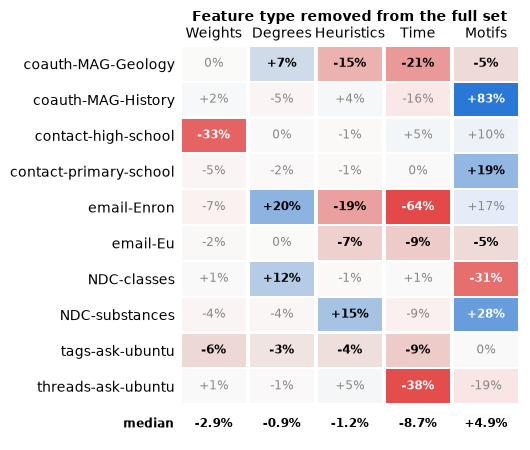

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

RESULTS = 'results'

DATASETS = ['coauth-MAG-Geology', 'coauth-MAG-History', 'contact-high-school', 'contact-primary-school',
            'email-Enron', 'email-Eu', 'NDC-classes', 'NDC-substances', 'tags-ask-ubuntu', 'threads-ask-ubuntu']
REMOVED = ['a-w', 'a-d', 'a-h', 'a-t', 'a-m']
LABELS = ['Weights', 'Degrees', 'Heuristics', 'Time', 'Motifs']

# % change vs the full set; "clear" = difference larger than the sum of the two stds
change = np.zeros((len(DATASETS), len(REMOVED)))
clear = np.zeros((len(DATASETS), len(REMOVED)), dtype=bool)
for i, ds in enumerate(DATASETS):
    full = pd.read_csv(f'{RESULTS}/{ds}/metrics/lr_a.csv')['performance']
    for j, f in enumerate(REMOVED):
        p = pd.read_csv(f'{RESULTS}/{ds}/metrics/lr_{f}.csv')['performance']
        change[i, j] = (p.mean() - full.mean()) / full.mean() * 100
        clear[i, j] = abs(p.mean() - full.mean()) >= p.std() + full.std()

cmap = LinearSegmentedColormap.from_list('div', ['#e34948', '#f0efec', '#2a78d6'])
norm = TwoSlopeNorm(vmin=-40, vcenter=0, vmax=40)

fig, ax = plt.subplots(figsize=(5.4, 4.6))
for i in range(len(DATASETS)):
    for j in range(len(REMOVED)):
        v = change[i, j]
        ax.add_patch(plt.Rectangle((j + 0.03, i + 0.03), 0.94, 0.94, lw=0,
                                   color=cmap(norm(np.clip(v, -40, 40))),
                                   alpha=1.0 if clear[i, j] else 0.28))
        text = '0%' if abs(v) < 0.5 else f'{v:+.0f}%'
        if clear[i, j]:
            color = 'white' if abs(v) > 22 else 'black'
            ax.text(j + 0.5, i + 0.5, text, ha='center', va='center', fontsize=8.5, color=color, fontweight='bold')
        else:
            ax.text(j + 0.5, i + 0.5, text, ha='center', va='center', fontsize=8.5, color='#898781')

# median row
for j, v in enumerate(np.median(change, axis=0)):
    ax.text(j + 0.5, len(DATASETS) + 0.55, f'{v:+.1f}%', ha='center', va='center', fontsize=8.5, fontweight='bold')
ax.text(-0.08, len(DATASETS) + 0.55, 'median', ha='right', va='center', fontsize=8.5, fontweight='bold')

ax.set_xlim(0, len(REMOVED))
ax.set_ylim(len(DATASETS) + 1, 0)
ax.set_xticks(np.arange(len(REMOVED)) + 0.5)
ax.set_xticklabels(LABELS)
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')
ax.set_xlabel('Feature type removed from the full set', fontweight='bold')
ax.set_yticks(np.arange(len(DATASETS)) + 0.5)
ax.set_yticklabels(DATASETS)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout()
plt.savefig('figures/ablation.pdf')
plt.show()

In [46]:
DATASETS = ['coauth-MAG-Geology', 'coauth-MAG-History', 'contact-high-school', 'contact-primary-school',
            'email-Enron', 'email-Eu', 'NDC-classes', 'NDC-substances', 'tags-ask-ubuntu', 'threads-ask-ubuntu']

# performance of the unsupervised baselines (AP / positive rate)
BASELINES = {
    'coauth-MAG-Geology':     {'HCN': 1.5646, 'HAA': 1.7038, 'HPA': 1.0859, 'SWA': 1.7256,  'SWG': 1.8145,  'SWH': 1.7137},
    'coauth-MAG-History':     {'HCN': 3.3487, 'HAA': 3.8942, 'HPA': 2.1176, 'SWA': 4.8290,  'SWG': 5.6508,  'SWH': 4.3489},
    'contact-high-school':    {'HCN': 1.6660, 'HAA': 1.7338, 'HPA': 0.9773, 'SWA': 2.9590,  'SWG': 4.1305,  'SWH': 3.6978},
    'contact-primary-school': {'HCN': 2.1128, 'HAA': 2.3021, 'HPA': 0.8341, 'SWA': 3.3144,  'SWG': 5.4731,  'SWH': 5.2179},
    'email-Enron':            {'HCN': 4.2332, 'HAA': 4.8926, 'HPA': 4.4434, 'SWA': 2.8335,  'SWG': 7.3681,  'SWH': 4.3785},
    'email-Eu':               {'HCN': 1.2059, 'HAA': 1.3010, 'HPA': 0.7798, 'SWA': 1.7201,  'SWG': 1.9722,  'SWH': 1.7828},
    'NDC-classes':            {'HCN': 1.5285, 'HAA': 1.3297, 'HPA': 2.1702, 'SWA': 1.1046,  'SWG': 1.3756,  'SWH': 1.4263},
    'NDC-substances':         {'HCN': 2.6368, 'HAA': 2.6817, 'HPA': 2.4891, 'SWA': 2.2003,  'SWG': 2.8192,  'SWH': 2.5855},
    'tags-ask-ubuntu':        {'HCN': 2.3872, 'HAA': 2.5033, 'HPA': 2.3255, 'SWA': 4.9768,  'SWG': 7.4204,  'SWH': 5.7571},
    'threads-ask-ubuntu':     {'HCN': 6.1801, 'HAA': 6.8488, 'HPA': 3.1958, 'SWA': 11.3249, 'SWG': 22.2064, 'SWH': 18.4103},
}

print(r'\begin{table}[t]')
print(r'\centering')
print(r'\caption{Performance of the six unsupervised baselines (average precision divided by the positive rate; '
      r"1 = random). Bold: best baseline in the dataset, reported as ``Best baseline'' in Table~\ref{tab:main}.}")
print(r'\label{tab:baselines}')
print(r'\small')
print(r'\begin{tabular}{lcccccc}')
print(r'\toprule')
print(r' & \multicolumn{3}{c}{Higher-order heuristics} & \multicolumn{3}{c}{Benson et al.\ (2018)} \\')
print(r'\cmidrule(lr){2-4}\cmidrule(lr){5-7}')
print(r'Dataset & HCN & HAA & HPA & SWA & SWG & SWH \\')
print(r'\midrule')
for ds in DATASETS:
    values = list(BASELINES[ds].values())
    best = max(values)
    cells = [f'\\textbf{{{v:.2f}}}' if v == best else f'{v:.2f}' for v in values]
    print(ds + ' & ' + ' & '.join(cells) + r' \\')
print(r'\bottomrule')
print(r'\end{tabular}')
print(r'\end{table}')

\begin{table}[t]
\centering
\caption{Performance of the six unsupervised baselines (average precision divided by the positive rate; 1 = random). Bold: best baseline in the dataset, reported as ``Best baseline'' in Table~\ref{tab:main}.}
\label{tab:baselines}
\small
\begin{tabular}{lcccccc}
\toprule
 & \multicolumn{3}{c}{Higher-order heuristics} & \multicolumn{3}{c}{Benson et al.\ (2018)} \\
\cmidrule(lr){2-4}\cmidrule(lr){5-7}
Dataset & HCN & HAA & HPA & SWA & SWG & SWH \\
\midrule
coauth-MAG-Geology & 1.56 & 1.70 & 1.09 & 1.73 & \textbf{1.81} & 1.71 \\
coauth-MAG-History & 3.35 & 3.89 & 2.12 & 4.83 & \textbf{5.65} & 4.35 \\
contact-high-school & 1.67 & 1.73 & 0.98 & 2.96 & \textbf{4.13} & 3.70 \\
contact-primary-school & 2.11 & 2.30 & 0.83 & 3.31 & \textbf{5.47} & 5.22 \\
email-Enron & 4.23 & 4.89 & 4.44 & 2.83 & \textbf{7.37} & 4.38 \\
email-Eu & 1.21 & 1.30 & 0.78 & 1.72 & \textbf{1.97} & 1.78 \\
NDC-classes & 1.53 & 1.33 & \textbf{2.17} & 1.10 & 1.38 & 1.43 \\
NDC-substances & 2.64

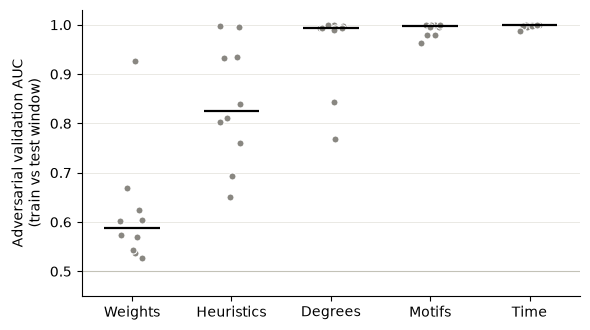

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = 'results'

GROUPS = ['weight', 'heuristics', 'degree', 'motifs', 'time']      # names in the 'features' column
LABELS = ['Weights', 'Heuristics', 'Degrees', 'Motifs', 'Time']

adv = pd.read_csv(f'{RESULTS}/adversarial_validation.csv')
adv = adv[(adv['split1'] == 'train') & (adv['split2'] == 'test')]
auc = adv.groupby(['features', 'dataset'])['auc'].mean()          # mean over folds

fig, ax = plt.subplots(figsize=(6.0, 3.4))
rng = np.random.default_rng(0)      # fixed jitter
for j, g in enumerate(GROUPS):
    y = auc[g]
    x = j + rng.uniform(-0.12, 0.12, size=len(y))
    color = '#898781'
    ax.scatter(x, y.values, s=26, color=color, edgecolor='white', linewidth=0.8, zorder=3)
    ax.hlines(y.median(), j - 0.28, j + 0.28, color='black', lw=1.6, zorder=4)

ax.axhline(0.5, color='#c3c2b7', lw=0.8)
ax.set_xticks(range(len(GROUPS)))
ax.set_xticklabels(LABELS)
ax.set_ylim(0.45, 1.03)
ax.set_ylabel('Adversarial validation AUC\n(train vs test window)')
ax.grid(axis='y', color='#e1e0d9', lw=0.5)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/adversarial_validation.pdf')
plt.show()

In [58]:
import pandas as pd

WITHIN = 'results/test_window_cv/summary.csv'      # output of within_window.py

DATASETS = ['coauth-MAG-Geology', 'coauth-MAG-History', 'contact-high-school', 'contact-primary-school',
            'email-Enron', 'email-Eu', 'NDC-classes', 'NDC-substances', 'tags-ask-ubuntu', 'threads-ask-ubuntu']

df = pd.read_csv(WITHIN).set_index('dataset')

print(r'\begin{table}[t]')
print(r'\centering')
print(r'\caption{Logistic regression on all features, evaluated on the test window. Preceding window: trained on '
      r'the preceding window (standard setting, as in Table~\ref{tab:main}). Within window: trained within the test '
      r'window itself (5-fold split of the candidates, same hyperparameters); a diagnostic, not a forecast. '
      r'SWG on the same window for reference. Group A: learning beats the best baseline in Table~\ref{tab:main}; '
      r'group B: it does not. Mean $\pm$ std over 5 seeds; 1 = random.}')
print(r'\label{tab:within}')
print(r'\small')
print(r'\begin{tabular}{lcccc}')
print(r'\toprule')
print(r'Dataset & Group & SWG & Preceding window & Within window \\')
print(r'\midrule')
for ds in DATASETS:
    r = df.loc[ds]
    print(f"{ds} & {r['group']} & {r['SWG']:.2f} & "
          f"{r['earlier_window_mean']:.2f} $\\pm$ {r['earlier_window_std']:.2f} & "
          f"{r['test_window_mean']:.2f} $\\pm$ {r['test_window_std']:.2f} \\\\")
print(r'\bottomrule')
print(r'\end{tabular}')
print(r'\end{table}')

\begin{table}[t]
\centering
\caption{Logistic regression on all features, evaluated on the test window. Preceding window: trained on the preceding window (standard setting, as in Table~\ref{tab:main}). Within window: trained within the test window itself (5-fold split of the candidates, same hyperparameters); a diagnostic, not a forecast. SWG on the same window for reference. Group A: learning beats the best baseline in Table~\ref{tab:main}; group B: it does not. Mean $\pm$ std over 5 seeds; 1 = random.}
\label{tab:within}
\small
\begin{tabular}{lcccc}
\toprule
Dataset & Group & SWG & Preceding window & Within window \\
\midrule
coauth-MAG-Geology & A & 1.81 & 3.18 $\pm$ 0.08 & 4.21 $\pm$ 0.03 \\
coauth-MAG-History & B & 5.65 & 3.76 $\pm$ 1.20 & 7.96 $\pm$ 0.61 \\
contact-high-school & B & 4.13 & 3.74 $\pm$ 0.28 & 4.51 $\pm$ 0.50 \\
contact-primary-school & B & 5.47 & 4.69 $\pm$ 0.33 & 5.78 $\pm$ 0.12 \\
email-Enron & A & 7.37 & 11.75 $\pm$ 0.75 & 24.70 $\pm$ 4.35 \\
email-Eu & A & 1.9